In [38]:
# still have the issue of passing in variables to both sets of analysis
# use argparse or a new python 'module', but for the module we'd have to use importlib.reload()
# to avoid restarting the kernel everything I want to change the binning (or something similar)

# from Zhiheng's message
# I would say that the position of the collimator changed a little bit
# but we also redid the measurement, so the 28.5 would be more accurate.
# We also rotated the collimator on 0303, so I'd say everything before that
# is closer to 28cm, and everything after is closer to 28.5


#### What does this code do (eventually) ####

## notes to fix the chi2 global value

# need to sort out the Nbins/dof stuff. sum chi2 before reducing to handle the single free parameter over many bins
# but maybe have to do some probability stuff. 

# some errors don't come through. like the number of counts in background data. The only errors in chi2 some from
# the MC counts (and should include the data counts). Also what about bin-to-bin fluctutions, counts are correlated
# like if something isn't in 3PE bin it will be in 2 or 4PE bin
# I guess this is why our chi2 is lower than 1?

# also the binrange, need to look at both datasets to make sure in poisson--> gaussian regime.
# maybe sum the uncertainties in the denominator of chi2 calculation? but that doesn't make total sense

# what would the complete likelihood look like? not too bad, just sampling from poisson a bunch of times.

In [39]:
# need to implement LP filter. also in G4_runClasses and mac. right now set to false
# see xxLP in code

In [40]:
## Python Stuff
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json5

os.environ.get("ROOTSYS")

"""
run with:
see code1analysis/ana1_Cs_bkgs_v1.ipynb for instructions on running jlab see bashprofile
"""

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(300)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
ROOT.enableJSVis()
# ROOT.disableJSVis()

In [41]:
## prepping to get tools for real data
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME"))

# so we can use makeDataObj.py
THISPATH = os.environ.get("CF4HOME")+"/comp1/"
sys.path.append(THISPATH)

## Loading Atown's tools
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

print(sys.path)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/Batch

In [99]:
##### user controls #####
THISPATH = os.environ.get("CF4HOME")+"/comp1/"
with open(THISPATH+'config.json', 'r') as file:
  config = json5.load(file)

NBINS = config.get("global_analysis").get("nBins")
BINLOW = config.get("global_analysis").get("binLow")
BINHIGH = config.get("global_analysis").get("binHigh")
print(NBINS, BINLOW, BINHIGH)

FIRSTBIN = config.get("global_analysis").get("range_lowBin")
print("firstBin:", FIRSTBIN)

GLOBALVERBOSE = config.get("global_analysis").get("verbose")

USEAVG = config.get("data_analysis").get("avg_background")
USEAVG = False

hScale = config.get("cesiumBareData").get("hScale")

NCA = config.get("mc_analysis").get("NCA")


# config.get("data_analysis").get("defData_Path")
# config.get("cesiumBareData").get("bkgList")


50 0.5 100.5
firstBin: 0


In [100]:
## -------- Loading in real CS data -------- ##
checkName = 'rcList'
if checkName in globals() or checkName in locals():
   print(f"{checkName} is declared, not reloading data")
else:
    print(f"{checkName} is not declared. running code")
    makeDataArg = str(THISPATH + "makeDataObj_csBare.py")
    %run $makeDataArg
# %run $makeDataArg

# xx is running this multiple times okay? 
# ------------- Get and build the bkg corrected spectra ------------- ##
print("\n Bare:")
for rc in rcl_cs_bare_heights:
  rc.FindClosestRC(rcl_Bkg_0310)

  if USEAVG:
    rc.BuildCorrSpectrum(hNPE_bkg_0310)
  else:
    rc.BuildCorrSpectrum()
     
  rc.setup_forComparison()
  print(rc.mHeight)

print("\n Filtered")
for rc in rcl_cs_lp_heights:
  rc.FindClosestRC(rcl_Bkg_0411)

  if USEAVG:
    rc.BuildCorrSpectrum(hNPE_bkg_0411)
  else:
    rc.BuildCorrSpectrum()

  rc.setup_forComparison()
  print(rc.mHeight)

rcList is declared, not reloading data

 Bare:
26.5
28
30.5
32
34.5

 Filtered
32.0
30.5
28.5
26


In [101]:
# this is all the files in a single folder
class RealDataSet(object):

  def __init__(self):
    
    ## only Cs data right now
    self.mCsBare = []
    self.mCsLP = []

    self.mCoBare = []
    self.mCoLP = []

    return

  def print(self):
    
    return
  
  ## not using this. use single comparator object instead
  # def passMCset(self, mcData, options: str = ""):

  #   self.checkMapping()
  #   return
  
  # def calcChi2():

  
  # def plot_singleRows(self, fig: plt.figure, selection = "mCsBare",):
  #   Nrows = len(getattr(self, selection))

  #   for i, rc in enumerate(getattr(self, selection)):
  #     ax = fig.add_subplot.hist(Nrows, 1, i+1)
  #     ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype = "step", label = "data " + str(hScale - rcBare_55cm.mHeight) + " cm")
  #   return


In [102]:
realData = RealDataSet()

## looking for specific RC objects by height (data runs)
# SORTING.findRCbyHeight = lambda h, rclist: next((rc for rc in rclist if rc.GetHeight() == h), None)
cs_bare_heights = [x for x in cs_bare_heights if x != 34.5] # get rid of the data below SiPM
print(cs_bare_heights)

# selecting the RC objects to pass to realData
bareCsData_rc = [SORTING.findRCbyHeight(h, rcl_cs_bare_heights) for h in cs_bare_heights] # prune off 34.5 one
bareCsData_rc = sorted(bareCsData_rc, key=lambda rc: hScale - rc.mHeight) # sorting
print(type(bareCsData_rc[0]))

print("bare Cs data Heights", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in bareCsData_rc]; print("")


rcl_cs_lp_heights = sorted(rcl_cs_lp_heights, key=lambda rc: hScale - rc.mHeight) # sorting
lpCsData_rc = rcl_cs_lp_heights # rcl comes from getDataObjs script
print("\nlp Cs data Heights", end = ": ")
[print(hScale - rc.mHeight, end = " ") for rc in lpCsData_rc]; print("")

bareCsData_rc[0].print()

## assigning rc lists to realData object
realData.mCsBare = bareCsData_rc
realData.mCsLP = lpCsData_rc
# xxLP do others here
# mapping of dif heights will be an issue. dif heights in MC or change h values in rc objects

for rc in realData.mCsBare:
  print(rc.GetRunTime())

[26.5, 28, 30.5, 32]
<class 'helpers.anaStructs.RunClass'>
bare Cs data Heights: 0.0 1.5 4.0 5.5 

lp Cs data Heights: 0.0 1.5 3.5 6.0 

runID: 202203101534
Nevents: 24688.00,   time: 13.01 min
average Rate: 31.62 Hz
height = 32.00
chID:0: spe = 151.66 +/- 0.38     maxChi2 = 0.00
chID:1: spe = 154.86 +/- 0.43     maxChi2 = 0.00
chID:2: spe = 154.51 +/- 2.68     maxChi2 = 0.00
780.804671136
3276.8955991280004
1584.009241896
2029.1536702320002


Text(0, 0.5, 'chi2')

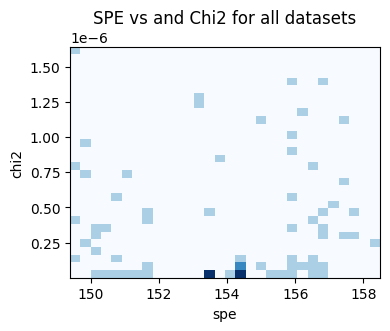

In [103]:
## checking spe and chi2 values
plt.figure(figsize=(4, 3))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.title("SPE vs and Chi2 for all datasets")
plt.xlabel("spe")
plt.ylabel("chi2")
# plt.show()

In [104]:
# this will take in a folder and create the MC dataset
# # and an set 

# Geant4 code and helpers
sys.path.append(os.environ.get("CF4G4"))
import Batch.helpers.FileGetters as FG

from Batch.helpers.G4_runClasses import *
from Batch.helpers.G4_macHelpers import *

# this is all the files in a single folder
class MCdataSet(object):

  def __init__(self, folderPath: str, verbose = 1):
    
    files = FG.get_all_root_files(folderPath)
    self.fpath = folderPath
    if verbose == 1:
      print(files)
    # open everything as FullMCRun
    # sort by mRunPars

    # entire trackers
    self.mAllRuns = [FullMCRun(macName = f[:-len(".root")], verbose = verbose) for f in files]
    

    ## loading (Bare) Cs data
    self.mCsBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Cs137")]
    self.mCsBareList = sorted(self.mCsBareList, key=lambda rc: rc.mRunPars.gammaHeight) # sorting
    # [print(type(mc.mRunPars.gammaHeight)) for mc in self.mCsBareList]
    self.mCsBareRateScaling = 0.1 #float
    
    self.mCsLpList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Cs137")]

    ## Co data
    # self.mCoBareList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == False and mc.mRunPars.gammaSrc == "Co57")]
    # self.mCoLPList = [mc for mc in self.mAllRuns if (mc.mRunPars.lpFilter == True and mc.mRunPars.gammaSrc == "Co57")]
    self.mCoRateScaling = 0.1 #float

    ## other data\
    return

  def doCAcorrection_BinomialMC(self, nCA):
    done = [mc.doCAcorrection_BinomialMC(NCA) for mc in self.mAllRuns]
    return
  
  # for "mNPE", "mNPE_corr", call one of the doCAcorrection first
  def setup_forComparison(self, Nbins = 100, lowRange = 0.5, maxRange = 100.5, variable = "mNPE"):
    done = [mc.setup_forComparison(NBINS, lowRange, maxRange, variable) for mc in self.mAllRuns]
    return
  
  # def compare_dicts(dict1, dict2):
  #   return all(dict1.get(key) == dict2.get(key) for key in dict1.keys())

  def print(self):
    
    return
  
  # check that all physPars are the same (they should be)
  # detPars aren't implemented yet (only PDE)
  def check_physPars_andDetPars(self, verbose = 1):

    physParList = [mc.mPhysPars for mc in self.mCsBareList + self.mCsLpList]
    if verbose == 2:
      [print(mc.mPhysPars.__dict__, "\n") for mc in self.mCsBareList]
    a = all(physParList[0] == p1 for p1 in physParList[1:])
    if a == True:
      if verbose:
        print("phys Pars consistent for", self.fpath)
        print(self.mCsBareList[0].mPhysPars)
      return a
    else:
      print("ERROR, physPars inconsistent for", self.fpath)
    return a

In [105]:
pBatch1 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/"

# 8 is the best fit right now
mc1 = MCdataSet(pBatch1+"16/")

# setup for physics comparisons
mc1.doCAcorrection_BinomialMC(config.get("mc_analysis").get("NCA"))
mc1.setup_forComparison(NBINS, BINLOW, BINHIGH)

# len(mc1.mCsBareList)
# mc1.mCsBareList[0].mPhysPars.ly = 1000

# blah = FullMCRun(pBatch1+"/0/"+"Cs137_ly_3000_h_0_ly")
for mc in mc1.mCsBareList:
  h = mc.mRunPars.gammaHeight
  print(h)

mc1.check_physPars_andDetPars(verbose = True)
# print(mc1.mCsBareList[0].mPhysPars.__dict__)
# np.mean(mc1.mCsBareList[3].mNPE)

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_5d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_1d5_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_4d0_ly.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_0_ly.root']
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_5d5_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_1d5_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_4d0_ly.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/geant4_cf4/batchOutput/16/Cs137_ly_12000_h_0_ly.root
0.0
1.5
4.0
5.5
phys Pars consisten

True

In [106]:
a = np.array([50, 11, 12, 11, 9])
np.where(a < 10)[0][0]
a[1:4]

array([11, 12, 11])

In [107]:
# should have this working as a two way object (rc and mc also know about it)
class rcMCpair(object):

  def __init__(self, rc, mc):
    self.mc = mc
    self.rc = rc
    self.height = mc.mRunPars.gammaHeight
    self.countLimit = 10
    return
  
  def SetBinRanges(self, firstBin = 1):

    self.firstBin = firstBin
    self.lastBin = np.where(self.rc.mBin_rawCounts < self.countLimit)[0][0]

    # badly handle bins less than 10
    if self.rc.mBin_rawCounts[self.lastBin] <= 0:
      self.lastBin -= 1
    while self.mc.mRaw_Counts[self.lastBin] <= self.countLimit:
      self.lastBin -= 1
    return

  ##----------##
  def GuessScaling(self):

    if not hasattr(self, "lastBin") or not hasattr(self, "firstBin"):
      print("WARNING in GuessScaling: first and lastBin not set. Call SetBinRanges() first")
      return -1

    # analytic scaling
    dataArea = sum(self.rc.mBin_rawCounts[self.firstBin:self.lastBin]) / self.rc.GetRunTime() #xx
    self.mcScale = dataArea / np.sum(self.mc.mRaw_Counts[self.firstBin:self.lastBin])

    # print(np.sum(self.rc.mBin_rawCounts[self.firstBin:self.lastBin]))
    # print(self.mcScale * np.sum(self.mc.mRaw_Counts[self.firstBin:self.lastBin]))
    # print(self.mcScale)
    
    return self.mcScale # this is now proportional to the runtime. has units 1/time

  def GetMaxBin(self, scaling, rawCounts = True):
    if rawCounts:
      a = max(np.maximum(self.rc.mBin_rawCounts, scaling * self.mc.mRaw_Counts * self.rc.GetRunTime()))
      return a
    else:
      a = max(np.maximum(self.rc.mBin_rawCounts / self.rc.GetRunTime(), scaling * self.mc.mRaw_Counts ))
      return a

  ##----------##
  def computeChi2_reduced(self, scaling):
    if not hasattr(self, "lastBin") or not hasattr(self, "firstBin"):
      print("WARNING in rcmcPair.computeChi2_reduced: first and lastBin not set. Call SetBinRanges() first")
      return -1
      # self.SetBinRanges(firstBin)
      # return -1
  
    mcBins = scaling * (self.mc.mRaw_Counts[self.firstBin:self.lastBin])
    dataBins = self.rc.mBin_rawCounts[self.firstBin:self.lastBin]  / self.rc.GetRunTime()
    self.chi2 = np.sum((dataBins - mcBins)**2/mcBins)
    self.nbinsUsed = self.lastBin - self.firstBin
    self.ndof = self.lastBin - self.firstBin #+1 # i think +1 here is right? NO because lastBin is excluded. so if firstBin = 1, lastBin = 5, bins 1-4 are used. 5 - 1 = 4, 5 - 1 -1 = 3 which is wrong
    self.redChi2 = self.chi2/(self.ndof)
    # xx I was initally subtracting -1 from denominator above. but that reduces for the scaling too many times
    # total statistic = (X1 + X2 + X3 + ...)/(ndof1 + nbins2 + nbins3 + ... - nParameters(1 here))
    # I don't like this because it is not summing the reduced chi2, but summing all then reducing which we thought gave a different absolute value
    # I was doing extra -1 subtraction for every run
    return self.redChi2

# do i make another object to track chi2 scores, nuisance pars, etc?

import scipy.optimize as spOpt
from helpers.anaStructs import * # includes SORTING class/namespace
########################################
class Comparator(object):

  def __init__(self, realData):

    self.mMCDataSet = None
    self.mRealData = realData # this never changes

    self.hScale = hScale

    ## Cesium
    self.csBareMap = [None] * len(self.mRealData.mCsBare)
    self.csBareNuis = -1
    self.csBareChi2 = -1

    return
  
  def loadNewG4(self, mc, verbose = 1):
    # load it
    self.mMCDataSet = mc

    # give it a physPars copy
    return True

  ## ensure 
  def do_mapping(self, heightsWanted = []):
    # how to track heights and map them to one another. 

    # check lengths
    if (len(self.mMCDataSet.mCsBareList) != len(self.mRealData.mCsBare)):
      print("mc csBare list not equal to realData list")
      return False
    # print(len(self.mMCDataSet.mCsBareList))
    # print(len(self.mRealData.mCsBare))

    # doing BareCs mapping
    for i, mc in enumerate(self.mMCDataSet.mCsBareList): # here mc is a FullMCRun object
      h = mc.mRunPars.gammaHeight # get height
      rc_withHeight = SORTING.findRCbyHeight(self.hScale - h, self.mRealData.mCsBare) # get real data
      # print(h, type(rc_withHeight))
      pair = rcMCpair(rc_withHeight, mc) # make pair object to map them together
      # print(hScale - rc_withHeight.mHeight, pair.mc.mRunPars.gammaHeight == self.hScale - rc_withHeight.mHeight) 
      self.csBareMap[i] = pair # assign pair to the map list
    
    # print(len(self.csBareMap))
    return True
  
  def SetBinRanges(self, firstBin = 1):
    [rcmc.SetBinRanges(firstBin) for rcmc in self.csBareMap] # Cs
    return
  
  def GuessOverallScaling(self): # call guess scaling for each pair to get overall scaling
    ## Cs 
    self.csGuess = np.sum([pair.GuessScaling() for pair in self.csBareMap])/len(self.csBareMap)
    return self.csGuess

  def getFullReducedChi2(self, scaling = None):
    if scaling == None:
      scaling = self.GuessOverallScaling()
    # cesium bare
    csBare_chi2 = np.sum([pair.computeChi2_reduced(scaling) for pair in self.csBareMap])
    return csBare_chi2

  # similar to above, but REDUCE after summing. precise with free parameter shared over runs but
  # not so accurate to sum everything then divide?
  # need to look up the math of summing random variables
  # def getFullChi2(self, scaling = None):
  #   if scaling == None:
  #     scaling = self.GuessOverallScaling()
  #   # cesium bare
  #   csBare_chi2 = np.sum([pair.computeChi2_reduced(scaling) for pair in self.csBareMap])
  #   return csBare_chi2

  # this is only for Cs data. need to add options here to specify what datasets
  def minimizeRateScaling(self, manual = False, func = "reducedChi", verbose = 0): # nuisance parameter for these dataSets
    csGuess = self.GuessOverallScaling() # sets up firstGuess member (for Cs)
    
    # tryAgain: add a couple attempts with improved minimizer
    # also add option to do manually (find min of some 1d space like above)
    # also allow option to specify which function gets passed.
    minOptions = {
      'maxiter': 1000,
      'disp': False,
      'xatol': 1e-5,
      'fatol':1e-5,
      }
    # result = spOpt.minimize(fun = self.getFullReducedChi2, method = "L-BFGS-B", options=minOptions, x0 = [csGuess], bounds = [[0.1*csGuess, 10.*csGuess]])
    result = spOpt.minimize(fun = self.getFullReducedChi2, method = "nelder-mead", options=minOptions, x0 = [csGuess], bounds = [[0.1*csGuess, 10.*csGuess]])
    if result.success == True:
      if verbose == 1:
        print(result)
      self.csBareNuis = result.x[0]
      self.csBareChi2 = result.fun
      return 1, result
    else:
      print(result)
      print("minimize rate scaling failed for xComp1 ")
      return 0, result

# find the scaling nuisance parameter (minimize chi2) for the Cs dataset.
# only Bare for now (only have BareMC data)
# def scaleCs(startValue):


# comparator.mc1.mCsBareList[0].mPhysPars.ly

In [109]:
comp1 = Comparator(realData)  # set it with real data
comp1.mMCDataSet = mc1  # set MC data/attributes

comp1.do_mapping() # put mc and rc objects together (correctly)
comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts

scaleGuess = comp1.GuessOverallScaling()

print("scaleGuess:", scaleGuess, "\n")
print("firstBin:", comp1.csBareMap[0].firstBin)

comp1.getFullReducedChi2(scaleGuess)

scalingX = np.linspace(scaleGuess/2., scaleGuess * 2., 4)
print("chi2s:")
[print(comp1.getFullReducedChi2(scale)) for scale in scalingX]

comp1.minimizeRateScaling()


scaleGuess: 0.0001374117377384357 

firstBin: 0
chi2s:
2.212089753400514
0.8726465667302312
1.6959531794041578
3.059947241914137


(1,
        message: Optimization terminated successfully.
        success: True
         status: 0
            fun: 0.8499636318980986
              x: [ 1.269e-04]
            nit: 8
           nfev: 16
  final_simplex: (array([[ 1.269e-04],
                        [ 1.267e-04]]), array([ 8.500e-01,  8.500e-01])))

firstBin: 0


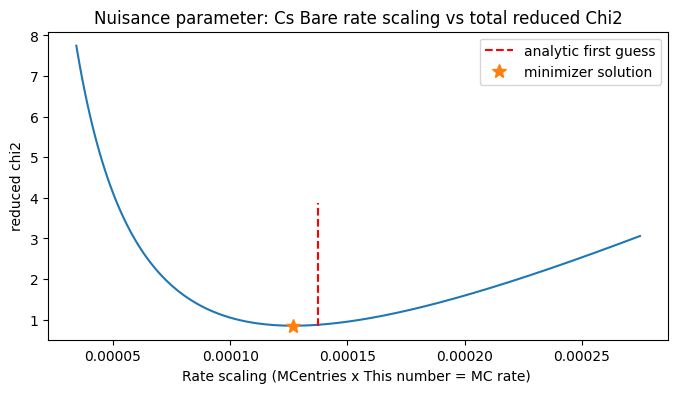

In [112]:
comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts
scaleGuess = comp1.GuessOverallScaling()
# print(scaleGuess)

# calculate the 1D space
scalingX = np.linspace(scaleGuess/4., scaleGuess * 2., 200)
chi2Full = np.array([comp1.getFullReducedChi2(scale) for scale in scalingX])

# plot it
fig, ax = plt.subplots(1, 1, figsize = (8, 4))

ax.plot(scalingX, chi2Full, "")
ax.vlines(scaleGuess, min(chi2Full), max(chi2Full)/2, color = "r", linestyle = "--", label = "analytic first guess")

nuis1 = comp1.minimizeRateScaling()
ax.plot(comp1.csBareNuis, comp1.getFullReducedChi2(comp1.csBareNuis), linewidth = 0, marker= "*", markersize = 10, label = "minimizer solution")

ax.set_title("Nuisance parameter: Cs Bare rate scaling vs total reduced Chi2")
ax.set_xlabel("Rate scaling (MCentries x This number = MC rate) ")
ax.set_ylabel("reduced chi2")
ax.legend()
print("firstBin:", comp1.csBareMap[3].firstBin)

plt.show()

0.8726465667302312


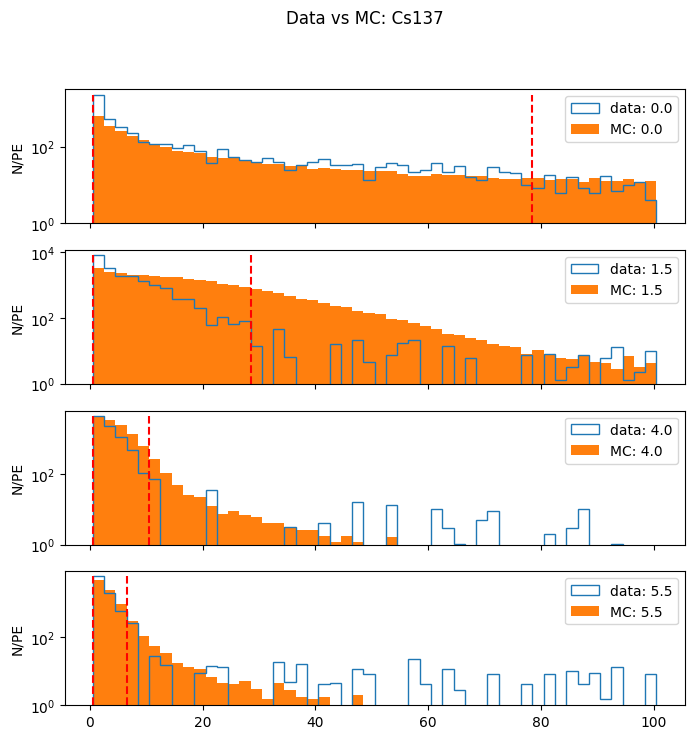

In [113]:
fig, axs = plt.subplots(4, 1, figsize = (8, 8), sharex=True)

mcScale = comp1.csBareNuis

# comp1.SetBinRanges(firstBin = FIRSTBIN) # set first bin as 1 and lastBin at 10 counts
# comp1.csBareMap[0].GetMaxBin(mcScale)
print(comp1.getFullReducedChi2())

for i, ax in enumerate(axs.flat):
  pair = comp1.csBareMap[i]
  rc = pair.rc
  mc = pair.mc
  ax.hist(x = rc.mBinX, bins = rc.mBin_edges, weights = rc.mBin_rawCounts, histtype="step", label = "data: " + str(comp1.hScale - rc.mHeight))
  ax.hist(x = mc.mBinX, bins = mc.mBin_Edges, weights = mc.mRaw_Counts * mcScale * rc.GetRunTime(), label = "MC: " + str(mc.mRunPars.gammaHeight))

  maxVal = pair.GetMaxBin(comp1.csBareNuis)
  ax.vlines([rc.mBinX[pair.firstBin], rc.mBinX[pair.lastBin]], ymin =1, ymax = maxVal, color = "red", linestyle = "--")
  ax.set_yscale("log")
  ax.set_ylim(1, maxVal*1.4)
  ax.set_ylabel("N/PE")
  ax.legend()


fig.suptitle("Data vs MC: Cs137")
plt.show()

In [114]:
## doing the real fucking thing ##
# comp2 = Comparator(realData)  # set it with real data

## loading in mc data forloop
# print(pBatch1)
all_items = os.listdir(pBatch1)
folders = [item for item in all_items if os.path.isdir(os.path.join(pBatch1, item))]
folders = sorted(folders, key=lambda x: int(x))
print("folders:", folders)
# break

firstBin_array = [0, 1, 2]
xLYs = [[] for _ in range(len(firstBin_array))]
yChi2s = [[] for _ in range(len(firstBin_array))]
zScaling = [[] for _ in range(len(firstBin_array))]
for folder in folders:

  # if int(folder) == 5:
  #   continue

  #open dataset
  mcData = MCdataSet(pBatch1 + folder + "/", verbose = 0) # open dataset

  # setup for physics comparisons
  mcData.doCAcorrection_BinomialMC(NCA)
  mcData.setup_forComparison(NBINS, BINLOW, BINHIGH)

  # do first sanity checks
  mcData.check_physPars_andDetPars(verbose = 0)

  comp1.mMCDataSet = mcData # point comp1 to mc data
  comp1.do_mapping() # put mc and rc objects together (correctly)

  for iFirstBin in firstBin_array:
    comp1.SetBinRanges(firstBin = iFirstBin) # set first bin as 1 and lastBin at 10 counts. could do directly on MC object...

    success, result = comp1.minimizeRateScaling(verbose = 0)

    ly = comp1.mMCDataSet.mCsBareList[0].mPhysPars.ly
    goodChi2 = comp1.csBareChi2
    nuis = comp1.csBareNuis

    if VERBOSE or success == 0:
      print("folder:", folder, f"LY: {ly}, chi2 = {goodChi2}, nuis = {nuis}, iBin = {iFirstBin} \n")
      print(comp1.getFullReducedChi2())
    else:
      xLYs[iFirstBin].append(ly)
      yChi2s[iFirstBin].append(goodChi2)
      zScaling[iFirstBin].append(nuis)

  # print(type(comp1.csBareMap[0]))
  # comp1.getFullReducedChi2(nuis1)
  # print(pBatch1 + folder + "/")
# comp2.mMCDataSet = mcData  # set MC data/attributes

# comp1.do_mapping() # put mc and rc objects together (correctly)
# comp1.SetBinRanges(firstBin = 1) # set first bin as 1 and lastBin at 10 counts
# nuis1 = comp1.minimizeRateScaling()

# # print(type(comp1.csBareMap[0]))
# comp1.getFullReducedChi2(nuis1)

folders: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17']


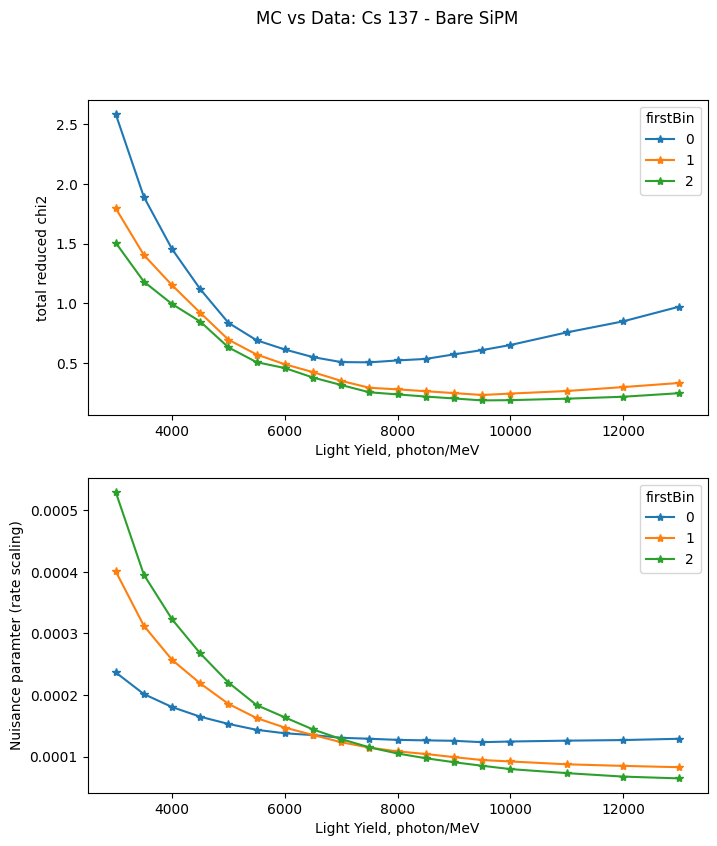

In [115]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (8, 9))

for iBin in firstBin_array:
  ax1.plot(xLYs[iBin], yChi2s[iBin], linestyle = "-", marker = "*", label = f"{iBin}")
  ax2.plot(xLYs[iBin], zScaling[iBin], linestyle = "-", marker = "*", label = f"{iBin}")


ax1.set_xlabel("Light Yield, photon/MeV")
ax1.set_ylabel("total reduced chi2")
ax1.legend(title="firstBin")
# ax1.set_ylim(450, 600)

ax2.set_xlabel("Light Yield, photon/MeV")
ax2.set_ylabel("Nuisance paramter (rate scaling)")
ax2.legend(title="firstBin")

fig.suptitle("MC vs Data: Cs 137 - Bare SiPM")

plt.show()